# Stage 3 — Exploring the Data

Three questions:
1. **Who churns?**
2. **What is churn linked to?**
3. **Where is the billing?**

Input: `data/processed/telco_clean.csv`. No modeling yet.

> Customers chose their own plans, so everything here shows what goes **together** with churn, not what causes it.

In [27]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#8a8a85"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "grid.color": "#e5e5e2", "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
})

def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png")

clean = pd.read_csv(ROOT / "data" / "processed" / "telco_clean.csv")

# is_churn: averaging it gives a churn rate.
# churned_charge: summing it gives billing from churned customers only (used in 3d).
clean["is_churn"] = (clean["Churn"] == "Yes").astype(int)
clean["churned_charge"] = clean["MonthlyCharges"] * clean["is_churn"]

BASELINE = clean["is_churn"].mean() * 100
MIN_CELL = 100   # below this, a group is too small to read a rate from

print(f"{len(clean):,} customers | baseline churn rate {BASELINE:.2f}%")

7,043 customers | baseline churn rate 26.54%


Most questions here are "for each group: how many customers, how many churned, what rate?" One helper does that, and always shows group size.

In [28]:
def churn_by(*columns):
    """Churn summary for one or more grouping columns, sorted by rate."""
    summary = (clean.groupby(list(columns), observed=True)["is_churn"]
               .agg(customers="size", churned="sum")
               .reset_index())
    summary["churn_rate"] = (summary["churned"] / summary["customers"] * 100).round(1)
    return summary.sort_values("churn_rate", ascending=False)


def wilson_ci(churned, customers, z=1.96):
    """95% Wilson interval for a proportion, as percentages.

    Wilson rather than the textbook normal interval: it stays inside [0, 1] and
    behaves sensibly for rates near zero, which matters here (two-year contracts
    churn at 2.8%).
    """
    p = churned / customers
    denominator = 1 + z ** 2 / customers
    centre = (p + z ** 2 / (2 * customers)) / denominator
    half_width = z * np.sqrt(p * (1 - p) / customers + z ** 2 / (4 * customers ** 2)) / denominator
    return ((centre - half_width) * 100).round(1), ((centre + half_width) * 100).round(1)

---
# 3a — One variable at a time

## Categorical variables

In [29]:
CATEGORICAL = [
    "gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines",
    "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod",
]

levels = []
for column in CATEGORICAL:
    table = churn_by(column).rename(columns={column: "level"})
    table.insert(0, "variable", column)
    table["level"] = table["level"].astype(str)
    levels.append(table)
levels = pd.concat(levels, ignore_index=True)

print(f"{len(levels)} levels | smallest group n = {levels['customers'].min()}")

43 levels | smallest group n = 682


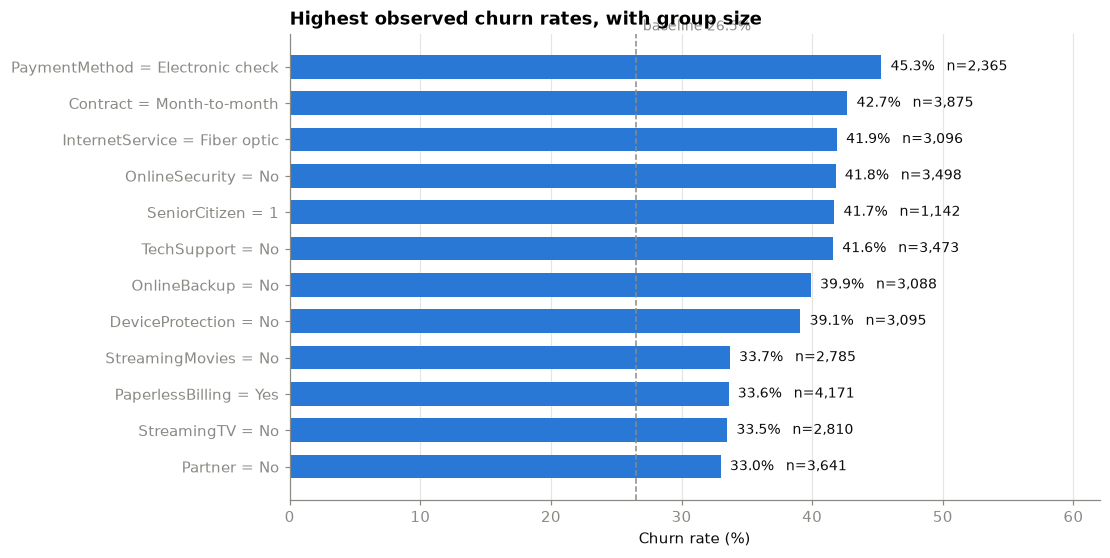

In [30]:
top = levels.nlargest(12, "churn_rate").iloc[::-1]

fig, ax = plt.subplots(figsize=(9.5, 5.5))
bars = ax.barh([f"{r.variable} = {r.level}" for r in top.itertuples()],
               top["churn_rate"], color=BLUE, height=0.65)
for bar, row in zip(bars, top.itertuples()):
    ax.text(bar.get_width() + 0.7, bar.get_y() + bar.get_height() / 2,
            f"{row.churn_rate:.1f}%   n={row.customers:,}", va="center", color=INK, fontsize=9)

ax.axvline(BASELINE, color=MUTED, linewidth=1, linestyle="--")
ax.text(BASELINE + 0.5, 12.0, f"baseline {BASELINE:.1f}%", color=MUTED, fontsize=9)
ax.set_title("Highest observed churn rates, with group size")
ax.set_xlabel("Churn rate (%)")
ax.set_xlim(0, 62)
ax.grid(axis="x"); ax.set_axisbelow(True)
save(fig, "01_top_churn_groups")
plt.show()

Every group has at least 682 customers, so no rate rests on a tiny sample.

**Watch out:** six add-on columns include "No internet service", which is the same 1,526 customers (7.4% churn) each time. Ranking by spread would push all six to the top for one reason. So we look at add-ons separately.

## Add-on services

In [5]:
internet = clean[clean["InternetService"] != "No"].copy()
ADDONS = ["OnlineSecurity", "TechSupport", "OnlineBackup",
          "DeviceProtection", "StreamingTV", "StreamingMovies"]

rows = []
for column in ADDONS:
    rates = internet.groupby(column)["is_churn"].agg(n="size", rate=lambda s: s.mean() * 100)
    rows.append({"service": column,
                 "has_it_n": int(rates.loc["Yes", "n"]),
                 "has_it_churn": round(rates.loc["Yes", "rate"], 1),
                 "lacks_it_n": int(rates.loc["No", "n"]),
                 "lacks_it_churn": round(rates.loc["No", "rate"], 1)})

addons = pd.DataFrame(rows)
addons["gap_pp"] = (addons["lacks_it_churn"] - addons["has_it_churn"]).round(1)

print(f"internet subscribers: {len(internet):,} | churn {internet['is_churn'].mean() * 100:.1f}%")
addons.sort_values("gap_pp", ascending=False)

internet subscribers: 5,517 | churn 31.8%


,service,has_it_n,has_it_churn,lacks_it_n,lacks_it_churn,gap_pp
0,OnlineSecurity,2019,14.6,3498,41.8,27.2
1,TechSupport,2044,15.2,3473,41.6,26.4
2,OnlineBackup,2429,21.5,3088,39.9,18.4
3,DeviceProtection,2422,22.5,3095,39.1,16.6
5,StreamingMovies,2732,29.9,2785,33.7,3.8
4,StreamingTV,2707,30.1,2810,33.5,3.4


Two clear groups:
- **Protective services** have big gaps: `OnlineSecurity` 27.2pp, `TechSupport` 26.4pp, `OnlineBackup` 18.4pp, `DeviceProtection` 16.6pp.
- **Streaming** barely matters (3.4pp, 3.8pp), and having it means slightly *lower* churn.

In 3c, streaming will look stronger than it is. That comes from the "No internet service" level, not from streaming.

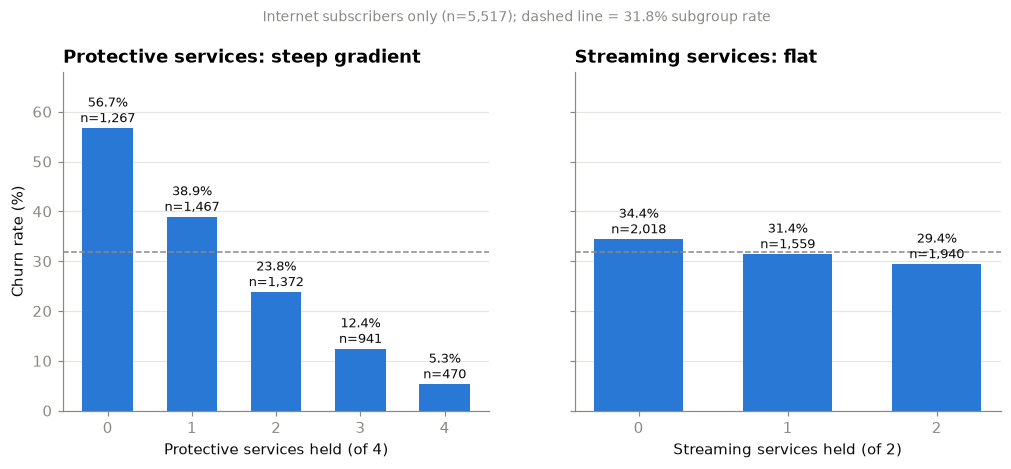

In [32]:
PROTECTIVE = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]
STREAMING = ["StreamingTV", "StreamingMovies"]
internet["n_protective"] = (internet[PROTECTIVE] == "Yes").sum(axis=1)
internet["n_streaming"] = (internet[STREAMING] == "Yes").sum(axis=1)

def by_count(column):
    counts = internet.groupby(column)["is_churn"].agg(customers="size", rate=lambda s: s.mean() * 100)
    return counts.round(1)

protective, streaming = by_count("n_protective"), by_count("n_streaming")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, data, title, xlabel in [
    (ax1, protective, "Protective services: steep gradient", "Protective services held (of 4)"),
    (ax2, streaming, "Streaming services: flat", "Streaming services held (of 2)"),
]:
    bars = ax.bar(data.index.astype(str), data["rate"], color=BLUE, width=0.6)
    for bar, rate, n in zip(bars, data["rate"], data["customers"]):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.2,
                f"{rate:.1f}%\nn={n:,}", ha="center", color=INK, fontsize=8.5)
    ax.axhline(internet["is_churn"].mean() * 100, color=MUTED, linewidth=1, linestyle="--")
    ax.set_title(title); ax.set_xlabel(xlabel)
    ax.grid(axis="y"); ax.set_axisbelow(True)

ax1.set_ylabel("Churn rate (%)"); ax1.set_ylim(0, 68)
fig.suptitle("Internet subscribers only (n=5,517); dashed line = 31.8% subgroup rate",
             x=0.5, y=1.02, fontsize=9, color=MUTED)
save(fig, "02_addon_service_gradient")
plt.show()

Churn drops from 56.7% (no protective services) to 5.3% (all four). But let's check what else changes across these groups.

In [33]:
internet.groupby("n_protective").agg(
    customers=("is_churn", "size"),
    churn_rate=("is_churn", lambda s: round(s.mean() * 100, 1)),
    median_tenure=("tenure", "median"),
    pct_month_to_month=("Contract", lambda s: round((s == "Month-to-month").mean() * 100, 1)),
)

,customers,churn_rate,median_tenure,pct_month_to_month
n_protective,,,,
0,1267,56.7,7.0,94.9
1,1467,38.9,19.0,80.4
2,1372,23.8,40.0,51.5
3,941,12.4,56.0,24.1
4,470,5.3,70.0,7.2


In [34]:
# Hold contract constant and see how much of the gradient survives.
(internet[internet["Contract"] == "Month-to-month"]
 .groupby("n_protective")["is_churn"]
 .agg(customers="size", churn_rate=lambda s: round(s.mean() * 100, 1)))

,customers,churn_rate
n_protective,,
0,1203,58.5
1,1180,45.2
2,707,36.5
3,227,22.9
4,34,26.5


**Much of this is really tenure and contract.** Customers with no add-ons have a median tenure of 7 months and 94.9% are month-to-month. Those with all four: 70 months and 7.2%. People add services over time.

Within the same contract type, the drop is **58.5% → 22.9%** (35.6pp) instead of **56.7% → 5.3%** (51.4pp). So about a third of the gap is contract and tenure; the rest holds up.

This doesn't mean selling TechSupport would lower churn. That needs a test.

## Numeric variables

In [35]:
clean.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].agg(["mean", "median", "std"]).round(2)

tenure               MonthlyCharges               TotalCharges                  
        mean median    std           mean median    std         mean   median      std
Churn                                                                                 
No     37.57   38.0  24.11          61.27  64.43  31.09      2549.91  1679.52  2329.95
Yes    17.98   10.0  19.53          74.44  79.65  24.67      1531.80   703.55  1890.82

`TotalCharges` mostly repeats tenure (see Stage 2), so we only plot tenure and monthly charges.

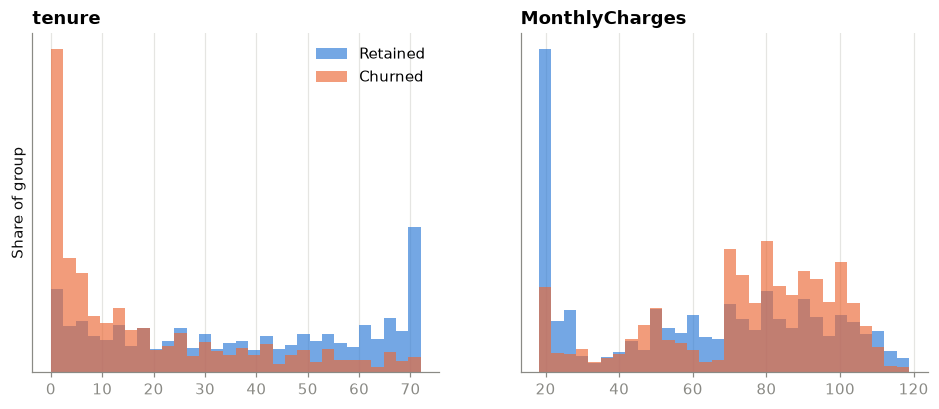

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
for ax, column in zip(axes, ["tenure", "MonthlyCharges"]):
    bins = np.histogram_bin_edges(clean[column], bins=30)
    # density=True: the groups differ in size (5,174 vs 1,869), so raw counts would
    # make "retained" look taller everywhere for trivial reasons.
    ax.hist(clean.loc[clean["is_churn"] == 0, column], bins=bins, density=True,
            color=BLUE, alpha=0.65, label="Retained")
    ax.hist(clean.loc[clean["is_churn"] == 1, column], bins=bins, density=True,
            color=ORANGE, alpha=0.65, label="Churned")
    ax.set_title(column); ax.set_yticks([])
    ax.grid(axis="x"); ax.set_axisbelow(True)

axes[0].legend(frameon=False); axes[0].set_ylabel("Share of group")
save(fig, "03_numeric_distributions")
plt.show()

In [37]:
# Month 0 kept separate: those 11 customers have no observed outcome (Stage 2).
clean["tenure_band"] = pd.cut(clean["tenure"], bins=[-1, 0, 6, 12, 24, 48, 72],
                              labels=["0", "1-6", "7-12", "13-24", "25-48", "49-72"])
churn_by("tenure_band").sort_values("tenure_band")

,tenure_band,customers,churned,churn_rate
0,0,11,0,0.0
1,1-6,1470,784,53.3
2,7-12,705,253,35.9
3,13-24,1024,294,28.7
4,25-48,1594,325,20.4
5,49-72,2239,213,9.5


In [38]:
# Confidence intervals, because we are about to compare adjacent quintiles.
clean["charge_quintile"] = pd.qcut(clean["MonthlyCharges"], 5)
quintiles = churn_by("charge_quintile").sort_values("charge_quintile").set_index("charge_quintile")

rate = quintiles["churned"] / quintiles["customers"]
margin = 1.96 * np.sqrt(rate * (1 - rate) / quintiles["customers"]) * 100
quintiles["ci_low"] = (quintiles["churn_rate"] - margin).round(1)
quintiles["ci_high"] = (quintiles["churn_rate"] + margin).round(1)
quintiles[["customers", "churn_rate", "ci_low", "ci_high"]]

,customers,churn_rate,ci_low,ci_high
charge_quintile,,,,
"(18.249, 25.05]",1420,9.2,7.7,10.7
"(25.05, 58.83]",1397,25.0,22.7,27.3
"(58.83, 79.1]",1411,29.8,27.4,32.2
"(79.1, 94.25]",1407,36.1,33.6,38.6
"(94.25, 118.75]",1408,32.8,30.3,35.3


**Tenure:** churn falls steadily, from **53.3%** in months 1–6 to **9.5%** at 49–72 months. Over half of new customers leave in the first six months.

**Monthly charges:** churn rises across the first four groups (9.2% → 25.0% → 29.8% → 36.1%). The top group is 32.8%, but that dip isn't significant (p = 0.065). So churn **levels off** at high prices rather than dropping. A single straight-line term won't fit this well.

---
# 3b — Combining variables

"Month-to-month" alone covers 3,875 very different people. Combining variables gives sharper groups.

Groups under 100 customers are flagged and ignored.

In [39]:
def interaction(column_a, column_b):
    table = churn_by(column_a, column_b)
    table["flag"] = np.where(table["customers"] < MIN_CELL, "small - ignore", "")
    return table

interaction("Contract", "InternetService")

,Contract,InternetService,customers,churned,churn_rate,flag
1,Month-to-month,Fiber optic,2128,1162,54.6,
0,Month-to-month,DSL,1223,394,32.2,
4,One year,Fiber optic,539,104,19.3,
2,Month-to-month,No,524,99,18.9,
3,One year,DSL,570,53,9.3,
7,Two year,Fiber optic,429,31,7.2,
5,One year,No,364,9,2.5,
6,Two year,DSL,628,12,1.9,
8,Two year,No,638,5,0.8,


In [40]:
interaction("Contract", "PaymentMethod")

,Contract,PaymentMethod,customers,churned,churn_rate,flag
2,Month-to-month,Electronic check,1850,994,53.7,
0,Month-to-month,Bank transfer (automatic),589,201,34.1,
1,Month-to-month,Credit card (automatic),543,178,32.8,
3,Month-to-month,Mailed check,893,282,31.6,
6,One year,Electronic check,347,64,18.4,
5,One year,Credit card (automatic),398,41,10.3,
4,One year,Bank transfer (automatic),391,38,9.7,
10,Two year,Electronic check,168,13,7.7,
7,One year,Mailed check,337,23,6.8,
8,Two year,Bank transfer (automatic),564,19,3.4,


In [41]:
interaction("InternetService", "PaymentMethod").head(6)

,InternetService,PaymentMethod,customers,churned,churn_rate,flag
6,Fiber optic,Electronic check,1595,849,53.2,
7,Fiber optic,Mailed check,258,110,42.6,
2,DSL,Electronic check,648,207,31.9,
4,Fiber optic,Bank transfer (automatic),646,187,28.9,
5,Fiber optic,Credit card (automatic),597,151,25.3,
3,DSL,Mailed check,613,127,20.7,


- **Month-to-month + fiber: 54.6% churn, 2,128 customers.** That's 30% of everyone. High rate *and* big.
- **Month-to-month + electronic check: 53.7%, 1,850 customers.**
- **Fiber + electronic check: 53.2%, 1,595 customers.**
- Within fiber, contract matters a lot: 54.6% (month-to-month) vs 7.2% (two-year).

**Our Stage 2 guess was wrong.** It's not automatic vs manual. Mailed check (manual) sits at 31.6%, close to the automatic methods (32.8%, 34.1%). Only electronic check stands out, at 53.7%.

In [42]:
tenure_contract = interaction("Contract", "tenure_band")
tenure_contract[tenure_contract["flag"] == ""]

,Contract,tenure_band,customers,churned,churn_rate,flag
0,Month-to-month,1-6,1413,780,55.2,
1,Month-to-month,7-12,581,244,42.0,
2,Month-to-month,13-24,737,278,37.7,
3,Month-to-month,25-48,802,264,32.9,
4,Month-to-month,49-72,342,89,26.0,
10,One year,49-72,634,82,12.9,
9,One year,25-48,518,55,10.6,
8,One year,13-24,197,16,8.1,
16,Two year,49-72,1263,42,3.3,
15,Two year,25-48,274,6,2.2,


**Long tenure doesn't cancel out the contract.** Month-to-month customers at 49–72 months still churn at **26.0%**, about average and 8× the two-year rate (**3.3%**).

That's based on 342 customers, our smallest group. Let's check how precise these numbers are.

In [43]:
# Confidence intervals for the groups we have named, not for every group in the notebook:
# these are the rates the business conclusions rest on.
headline = {
    "Month-to-month + Fiber":   clean["Contract"].eq("Month-to-month") & clean["InternetService"].eq("Fiber optic"),
    "Month-to-month + E-check": clean["Contract"].eq("Month-to-month") & clean["PaymentMethod"].eq("Electronic check"),
    "Fiber + E-check":          clean["InternetService"].eq("Fiber optic") & clean["PaymentMethod"].eq("Electronic check"),
    "Month-to-month, 49-72 mo": clean["Contract"].eq("Month-to-month") & clean["tenure"].between(49, 72),
    "Two year, 49-72 mo":       clean["Contract"].eq("Two year") & clean["tenure"].between(49, 72),
    "tenure 1-6 mo":            clean["tenure"].between(1, 6),
    "gender = Male":            clean["gender"].eq("Male"),
    "gender = Female":          clean["gender"].eq("Female"),
}

rows = []
for name, mask in headline.items():
    group = clean[mask]
    churned, customers = int(group["is_churn"].sum()), len(group)
    low, high = wilson_ci(churned, customers)
    rows.append({"segment": name, "customers": customers,
                 "churn_rate": round(churned / customers * 100, 1),
                 "ci_low": low, "ci_high": high, "half_width_pp": round((high - low) / 2, 1)})

pd.DataFrame(rows)

,segment,customers,churn_rate,ci_low,ci_high,half_width_pp
0,Month-to-month + Fiber,2128,54.6,52.5,56.7,2.1
1,Month-to-month + E-check,1850,53.7,51.5,56.0,2.2
2,Fiber + E-check,1595,53.2,50.8,55.7,2.5
3,"Month-to-month, 49-72 mo",342,26.0,21.7,30.9,4.6
4,"Two year, 49-72 mo",1263,3.3,2.5,4.5,1.0
5,tenure 1-6 mo,1470,53.3,50.8,55.9,2.6
6,gender = Male,3555,26.2,24.7,27.6,1.5
7,gender = Female,3488,26.9,25.5,28.4,1.4


**The big groups are very precise:** ±1 to ±2.6 points, while the gaps are 20–40 points. So we don't need confidence intervals everywhere.

Two worth noting:
- **Month-to-month, 49–72 months: 26.0% [21.7, 30.9].** The widest interval, but far from two-year's [2.5, 4.5]. The finding holds.
- **Gender: Male [24.7, 27.6] vs Female [25.5, 28.4].** Almost fully overlapping, so no difference.

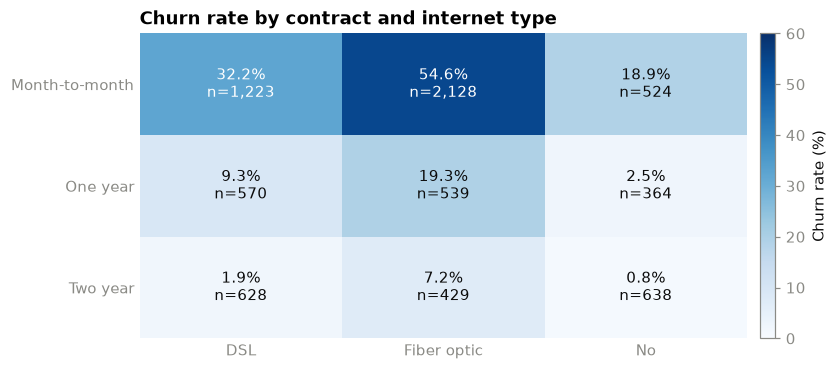

In [44]:
grid = churn_by("Contract", "InternetService")
order = ["Month-to-month", "One year", "Two year"]
rates = grid.pivot(index="Contract", columns="InternetService", values="churn_rate").loc[order]
sizes = grid.pivot(index="Contract", columns="InternetService", values="customers").loc[order]

fig, ax = plt.subplots(figsize=(7.5, 3.6))
# Sequential single hue for a magnitude: light to dark, no rainbow.
mesh = ax.imshow(rates.values, cmap="Blues", vmin=0, vmax=60, aspect="auto")
for i in range(rates.shape[0]):
    for j in range(rates.shape[1]):
        ax.text(j, i, f"{rates.values[i, j]:.1f}%\nn={sizes.values[i, j]:,}",
                ha="center", va="center", fontsize=9.5,
                color="white" if rates.values[i, j] > 32 else INK)

ax.set_xticks(range(rates.shape[1]), rates.columns)
ax.set_yticks(range(rates.shape[0]), rates.index)
ax.set_title("Churn rate by contract and internet type")
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
fig.colorbar(mesh, ax=ax, label="Churn rate (%)", fraction=0.03, pad=0.02)
save(fig, "04_contract_internet_heatmap")
plt.show()

---
# 3c — Statistical tests

We use chi-square (categorical variable vs churn).

With 7,043 customers, even tiny differences come out "significant". So we also use **Cramér's V**, which measures *how strong* a link is (0 = none, 1 = perfect), and rank by that.

Notes on V:
- The usual labels (0.1 small, 0.3 medium, 0.5 large) are rough rules of thumb, not real cutoffs.
- Every test here has a yes/no outcome, so the V values are comparable with each other.
- To decide if something *matters*, we look at the churn gap in percentage points.

We don't bin numeric columns just to run chi-square.

In [45]:
def cramers_v(chi2, n, shape):
    return np.sqrt(chi2 / (n * (min(shape) - 1)))

results = []
for column in CATEGORICAL:
    table = pd.crosstab(clean[column], clean["Churn"])
    chi2, p_value, _, expected = chi2_contingency(table)
    results.append({"variable": column, "levels": table.shape[0],
                    "chi2": round(chi2, 1), "p_value": p_value,
                    "cramers_v": round(cramers_v(chi2, table.values.sum(), table.shape), 3),
                    "min_expected": round(expected.min(), 1)})

tests = pd.DataFrame(results).sort_values("cramers_v", ascending=False)

# Running 16 tests inflates the chance of at least one false positive.
# Bonferroni is the blunt but defensible correction: divide alpha by the number of tests.
n_tests = len(tests)
bonferroni_alpha = 0.05 / n_tests
tests["survives_bonferroni"] = tests["p_value"] < bonferroni_alpha

print(f"n = {len(clean):,} customers, {n_tests} tests")
print(f"significant at p < 0.05        : {(tests['p_value'] < 0.05).sum()}")
print(f"family-wise error rate if none : {(1 - 0.95 ** n_tests):.0%} chance of >= 1 false positive")
print(f"Bonferroni alpha (0.05 / {n_tests})    : {bonferroni_alpha:.5f}")
print(f"surviving Bonferroni           : {tests['survives_bonferroni'].sum()}")

tests["p_value"] = tests["p_value"].apply(lambda p: "<0.001" if p < 0.001 else f"{p:.4f}")
tests

n = 7,043 customers, 16 tests
significant at p < 0.05        : 14
family-wise error rate if none : 56% chance of >= 1 false positive
Bonferroni alpha (0.05 / 16)    : 0.00313
surviving Bonferroni           : 13


,variable,levels,chi2,p_value,cramers_v,min_expected,survives_bonferroni
13,Contract,3,1184.6,<0.001,0.410,390.9,True
7,OnlineSecurity,3,850.0,<0.001,0.347,405.0,True
10,TechSupport,3,828.2,<0.001,0.343,405.0,True
6,InternetService,3,732.3,<0.001,0.322,405.0,True
15,PaymentMethod,4,648.1,<0.001,0.303,403.9,True
8,OnlineBackup,3,601.8,<0.001,0.292,405.0,True
9,DeviceProtection,3,558.4,<0.001,0.282,405.0,True
11,StreamingTV,3,374.2,<0.001,0.231,405.0,True
12,StreamingMovies,3,375.7,<0.001,0.231,405.0,True
14,PaperlessBilling,2,258.3,<0.001,0.191,762.1,True


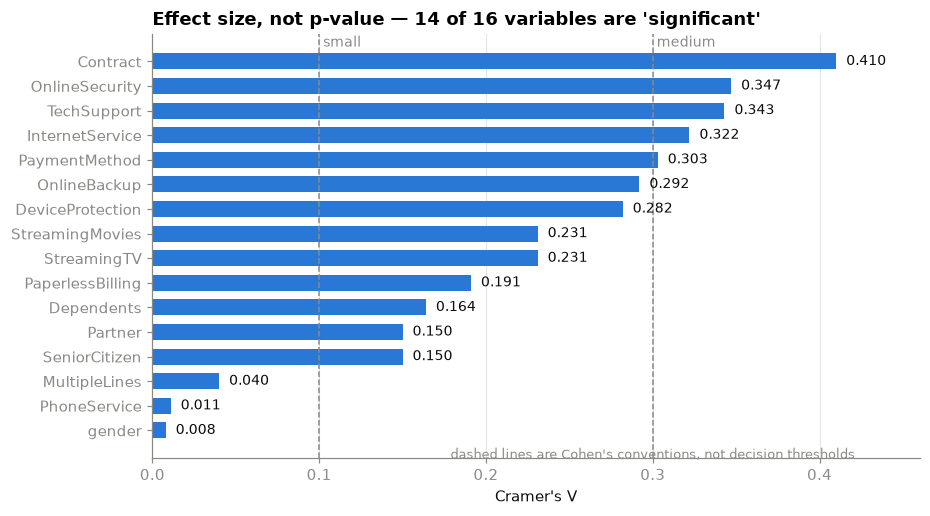

In [46]:
fig, ax = plt.subplots(figsize=(9, 5))
ordered = tests.sort_values("cramers_v")
bars = ax.barh(ordered["variable"], ordered["cramers_v"], color=BLUE, height=0.65)
for bar, value in zip(bars, ordered["cramers_v"]):
    ax.text(bar.get_width() + 0.006, bar.get_y() + bar.get_height() / 2,
            f"{value:.3f}", va="center", color=INK, fontsize=9)

for threshold, label in [(0.1, "small"), (0.3, "medium")]:
    ax.axvline(threshold, color=MUTED, linewidth=1, linestyle="--")
    ax.text(threshold, len(ordered) - 0.4, f" {label}", color=MUTED, fontsize=9)
ax.text(0.30, -1.15, "dashed lines are Cohen's conventions, not decision thresholds",
        color=MUTED, fontsize=8.5, ha="center")

ax.set_title("Effect size, not p-value — 14 of 16 variables are 'significant'")
ax.set_xlabel("Cramer's V")
ax.set_xlim(0, 0.46)
ax.grid(axis="x"); ax.set_axisbelow(True)
save(fig, "05_effect_sizes")
plt.show()

Every expected cell count is at least **181**, so chi-square is valid.

**14 of 16 variables are "significant".** Effect size narrows that down.

Example: `MultipleLines` has **p = 0.003 but V = 0.040**. Churn is 24.9% / 25.0% / 28.6%. Real, but too small to act on.

| V | Variables | Churn gap | Worth acting on? |
|---|---|---|---|
| 0.28–0.41 | `Contract` **0.410**, `OnlineSecurity`, `TechSupport`, `InternetService`, `PaymentMethod`, `OnlineBackup`, `DeviceProtection` | 27–40pp | Yes |
| 0.15–0.23 | `StreamingTV`/`StreamingMovies` 0.231 *(misleading, see below)*, `PaperlessBilling`, `Dependents`, `SeniorCitizen`, `Partner` | 13–18pp | Maybe |
| < 0.05 | `MultipleLines`, `PhoneService`, `gender` | 0.7–3.7pp | No |

A 13-point gap (like `Partner`) is still big in business terms, even if V calls it "small".

**Streaming is misleading.** Its V of 0.231 comes from "No internet service", not from streaming. The real streaming gap is 3.4pp. V can't tell you *which* level drives it, so you have to look.

### Many tests at once

Running 16 tests gives a 56% chance of at least one false alarm. Bonferroni correction uses α = 0.05/16 = **0.003125**.

**13 of 16 still pass.** The ones that fail: `gender` (p = 0.487), `PhoneService` (p = 0.339), and `MultipleLines` (p = 0.0035, just misses). We had already set `MultipleLines` aside for being small, so nothing changes. The strong results have p < 10⁻³⁶ and pass any correction.

---
# 3d — Billing from churned customers

A high churn rate in a small, cheap group matters less than a moderate rate in a big, expensive one. So we weight by `MonthlyCharges`.

**What this number is:** the monthly bills churned customers *were* paying. It's historical.

**What it isn't:**

| Not… | Because |
|---|---|
| a forecast | these customers already left |
| a yearly figure | ×12 assumes they'd all have stayed a year |
| profit | it ignores costs |
| recoverable | some would have left no matter what |

Good for comparing segments, not for a business case.

In [47]:
total_billing = clean["MonthlyCharges"].sum()
churned_billing = clean["churned_charge"].sum()

print(f"Total monthly billing  : ${total_billing:>10,.0f}  (n={len(clean):,})")
print(f"From churned customers : ${churned_billing:>10,.0f}  (n={clean['is_churn'].sum():,})")
print(f"\nChurned customers: {clean['is_churn'].mean():.1%} of the base, "
      f"{churned_billing / total_billing:.1%} of billing")
print(f"Average monthly charge: ${clean.loc[clean['is_churn'] == 1, 'MonthlyCharges'].mean():.2f} churned "
      f"vs ${clean.loc[clean['is_churn'] == 0, 'MonthlyCharges'].mean():.2f} retained")

Total monthly billing  : $   456,117  (n=7,043)
From churned customers : $   139,131  (n=1,869)

Churned customers: 26.5% of the base, 30.5% of billing
Average monthly charge: $74.44 churned vs $61.27 retained


In [48]:
def revenue_view(*columns):
    """Customers, churn rate and billing exposure per segment."""
    summary = (clean.groupby(list(columns), observed=True)
               .agg(customers=("is_churn", "size"),
                    churned=("is_churn", "sum"),
                    avg_charge=("MonthlyCharges", "mean"),
                    churned_billing=("churned_charge", "sum"))
               .reset_index())
    summary["churn_rate"] = (summary["churned"] / summary["customers"] * 100).round(1)
    summary["pct_of_churned_billing"] = (summary["churned_billing"] / churned_billing * 100).round(1)
    summary["avg_charge"] = summary["avg_charge"].round(2)
    return summary.sort_values("churned_billing", ascending=False)

revenue_view("Contract", "InternetService")

,Contract,InternetService,customers,churned,avg_charge,churned_billing,churn_rate,pct_of_churned_billing
1,Month-to-month,Fiber optic,2128,1162,87.02,100482.00,54.6,72.2
0,Month-to-month,DSL,1223,394,50.22,18367.25,32.2,13.2
4,One year,Fiber optic,539,104,98.78,10571.95,19.3,7.6
3,One year,DSL,570,53,61.40,3356.25,9.3,2.4
7,Two year,Fiber optic,429,31,104.57,3246.10,7.2,2.3
2,Month-to-month,No,524,99,20.41,1997.85,18.9,1.4
6,Two year,DSL,628,12,70.46,805.70,1.9,0.6
5,One year,No,364,9,20.82,190.25,2.5,0.1
8,Two year,No,638,5,21.78,113.50,0.8,0.1


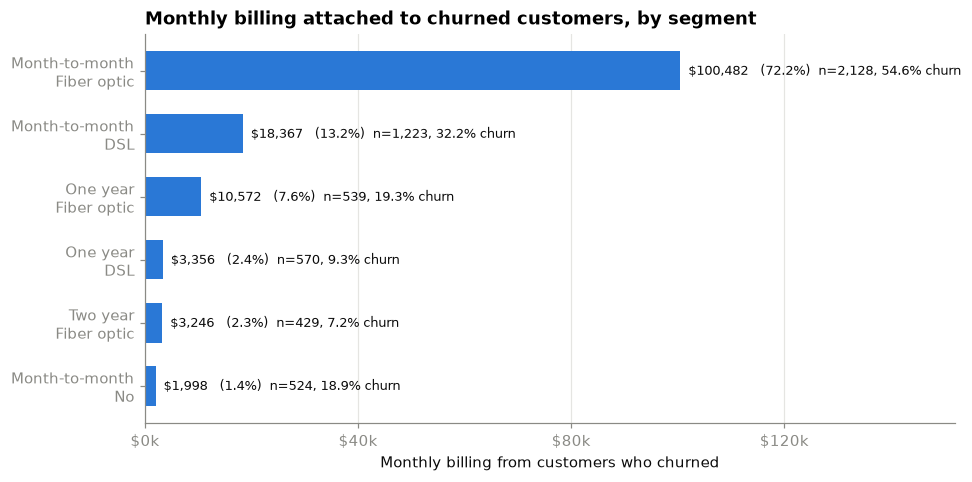

In [23]:
segments = revenue_view("Contract", "InternetService").head(6).iloc[::-1]

fig, ax = plt.subplots(figsize=(9.5, 4.6))
bars = ax.barh([f"{r.Contract}\n{r.InternetService}" for r in segments.itertuples()],
               segments["churned_billing"], color=BLUE, height=0.62)
for bar, row in zip(bars, segments.itertuples()):
    ax.text(bar.get_width() + 1500, bar.get_y() + bar.get_height() / 2,
            f"${row.churned_billing:,.0f}   ({row.pct_of_churned_billing:.1f}%)  "
            f"n={row.customers:,}, {row.churn_rate:.1f}% churn",
            va="center", color=INK, fontsize=8.5)

ax.set_title("Monthly billing attached to churned customers, by segment")
ax.set_xlabel("Monthly billing from customers who churned")
ax.set_xlim(0, 152000)
ax.set_xticks(range(0, 160000, 40000))
ax.set_xticklabels([f"${x // 1000:,}k" for x in range(0, 160000, 40000)])
ax.grid(axis="x"); ax.set_axisbelow(True)
save(fig, "06_revenue_exposure")
plt.show()

**Month-to-month + fiber is 72.2% of churned billing** (\$100,482 of \$139,131). Let's break that down.

In [49]:
segment = clean[clean["Contract"].eq("Month-to-month") & clean["InternetService"].eq("Fiber optic")]

print("Month-to-month + Fiber optic, as a share of the company\n")
print(f"  customers          {len(segment) / len(clean):>6.1%}   ({len(segment):,} of {len(clean):,})")
print(f"  churn rate         {segment['is_churn'].mean():>6.1%}   (company {clean['is_churn'].mean():.1%})")
print(f"  avg monthly charge  ${segment['MonthlyCharges'].mean():>5.2f}   (company ${clean['MonthlyCharges'].mean():.2f})")
print()
print(f"  -> share of all churners      {segment['is_churn'].sum() / clean['is_churn'].sum():>6.1%}")
print(f"  -> share of churned billing   {segment['churned_charge'].sum() / churned_billing:>6.1%}")

Month-to-month + Fiber optic, as a share of the company

  customers           30.2%   (2,128 of 7,043)
  churn rate          54.6%   (company 26.5%)
  avg monthly charge  $87.02   (company $64.76)

  -> share of all churners       62.2%
  -> share of churned billing    72.2%


**30.2% of customers → 62.2% of churners → 72.2% of churned billing.**

- 30% → 62%: this group churns a lot (54.6% vs 26.5%).
- 62% → 72%: they pay more (\$87.02 vs \$64.76 average).

So the 72% is **size + churn rate + price together**, and size is a big part. Month-to-month + electronic check churns almost as much; it's just smaller and cheaper.

What it means: **if you focus on billing, this is where it is.**

Highest-paying isn't the biggest share: two-year fiber averages \$104.57 but churns at only 7.2% (2.3% of churned billing).

**This isn't a target list yet.** That needs per-customer risk (Stages 4–5), customer value (Stage 6), and proof that offers work.

---
# Confounding: the fiber example

Fiber churns at **41.9%** vs **19.0%** for DSL. Is fiber bad, or are fiber customers just different?

In [50]:
for column in ["Contract", "PaymentMethod"]:
    print(f"{column} mix within each internet type (% of group)")
    print((pd.crosstab(clean["InternetService"], clean[column], normalize="index") * 100)
          .round(1).to_string(), "\n")

clean["n_protective"] = (clean[PROTECTIVE] == "Yes").sum(axis=1)
clean.groupby("InternetService").agg(
    customers=("is_churn", "size"),
    churn_rate=("is_churn", lambda s: round(s.mean() * 100, 1)),
    median_tenure=("tenure", "median"),
    median_monthly=("MonthlyCharges", "median"),
    mean_protective=("n_protective", "mean")).round(2)

Contract mix within each internet type (% of group)
Contract         Month-to-month  One year  Two year
InternetService                                    
DSL                        50.5      23.5      25.9
Fiber optic                68.7      17.4      13.9
No                         34.3      23.9      41.8 

PaymentMethod mix within each internet type (% of group)
PaymentMethod    Bank transfer (automatic)  Credit card (automatic)  Electronic check  Mailed check
InternetService                                                                                    
DSL                                   23.4                     24.5              26.8          25.3
Fiber optic                           20.9                     19.3              51.5           8.3
No                                    21.8                     21.7               8.0          48.6 



,customers,churn_rate,median_tenure,median_monthly,mean_protective
InternetService,,,,,
DSL,2421,19.0,29.0,56.15,1.86
Fiber optic,3096,41.9,30.0,91.68,1.42
No,1526,7.4,25.0,20.15,0.00


| | DSL | Fiber |
|---|---|---|
| Month-to-month | 50.5% | **68.7%** |
| Electronic check | 26.8% | **51.5%** |
| Median monthly charge | \$56.15 | **\$91.68** |
| Avg protective services | 1.86 | **1.42** |
| Median tenure | 29 months | 30 months |

Fiber customers have more of every risk factor, except tenure, which is about the same.

In [51]:
# Compare fiber and DSL only within the same contract and payment method.
subscribers = clean[clean["InternetService"] != "No"]
comparison = (subscribers
              .groupby(["Contract", "PaymentMethod", "InternetService"], observed=True)["is_churn"]
              .agg(customers="size", churn_rate=lambda s: round(s.mean() * 100, 1))
              .reset_index()
              .pivot_table(index=["Contract", "PaymentMethod"], columns="InternetService",
                           values=["customers", "churn_rate"]))

readable = ((comparison[("customers", "DSL")] >= MIN_CELL) &
            (comparison[("customers", "Fiber optic")] >= MIN_CELL))
gap = (comparison[("churn_rate", "Fiber optic")] - comparison[("churn_rate", "DSL")])[readable]

print(f"strata readable (>= {MIN_CELL} in both): {readable.sum()} of {len(comparison)}")
print(f"fiber above DSL in all of them: {(gap > 0).all()} | gap {gap.min():.1f} to {gap.max():.1f} pp")
comparison[readable]

strata readable (>= 100 in both): 9 of 12
fiber above DSL in all of them: True | gap 1.8 to 25.8 pp


churn_rate             customers            
InternetService                                 DSL Fiber optic       DSL Fiber optic
Contract       PaymentMethod                                                         
Month-to-month Bank transfer (automatic)       19.8        45.6     197.0       327.0
               Credit card (automatic)         27.0        41.6     185.0       293.0
               Electronic check                40.5        60.4     474.0      1307.0
               Mailed check                    30.8        50.7     367.0       201.0
One year       Bank transfer (automatic)        7.6        14.6     145.0       157.0
               Credit card (automatic)          9.9        15.3     172.0       150.0
               Electronic check                 9.5        26.0     116.0       196.0
Two year       Bank transfer (automatic)        1.3         9.3     224.0       162.0
               Credit card (automatic)          2.1         3.9     237.0       154.0

**The gap shrinks but doesn't go away.** In all 9 groups big enough to compare, fiber churns more, by 1.8 to 25.8 points. In the biggest group (month-to-month + electronic check) it's **40.5% DSL vs 60.4% fiber**. Three groups were skipped as too small.

So it's not *all* confounding either.

### What we can and can't say

**Can:** fiber customers churn more, even within the same contract and payment type. Part of the raw gap comes from them being different customers.

**Can't:** whether it's **service quality** (not measured), **price** (every fiber customer pays fiber prices), **competition** (not measured), or anything causal.

We can only adjust for what's in the data. This is a hypothesis to test, not a finding.

---
# Findings

Overall churn: **26.54%** (1,869 of 7,043).

### 1. Biggest differences

| Variable | Lowest | Highest | Gap |
|---|---|---|---|
| `tenure` | 49–72 months: 9.5% (n=2,239) | 1–6 months: 53.3% (n=1,470) | **43.8pp** |
| `Contract` | Two year: 2.8% (n=1,695) | Month-to-month: 42.7% (n=3,875) | **39.9pp** |
| `InternetService` | None: 7.4% (n=1,526) | Fiber optic: 41.9% (n=3,096) | **34.5pp** |
| `PaymentMethod` | Credit card: 15.2% (n=1,522) | Electronic check: 45.3% (n=2,365) | **30.1pp** |
| `OnlineSecurity` (internet users) | Has it: 14.6% (n=2,019) | Doesn't: 41.8% (n=3,498) | **27.2pp** |

Every group has 1,400+ customers, so these gaps are far beyond random noise (±1–3pp).

### 2. High-risk groups

- **Month-to-month + fiber: 54.6%, 2,128 customers** (30% of all)
- **Month-to-month + electronic check: 53.7%, 1,850**
- **Fiber + electronic check: 53.2%, 1,595**
- **Long tenure doesn't cancel contract:** month-to-month at 49–72 months churns 26.0% vs 3.3% for two-year

### 3. Strongest links

13 of 16 pass after correction. The strongest (Cramér's V): `Contract` 0.410, `OnlineSecurity` 0.347, `TechSupport` 0.343, `InternetService` 0.322, `PaymentMethod` 0.303, `OnlineBackup` 0.292, `DeviceProtection` 0.282, with churn gaps of 27–40pp.

### 4. What doesn't matter much

- **Gender:** 26.2% vs 26.9%. No difference.
- **Phone service:** no difference.
- **Multiple lines:** tiny (V = 0.040) and fails the correction.
- **Streaming:** 3.4–3.8pp. Its higher V is misleading.
- **Add-on services:** about a third of their effect is really tenure and contract.
- **Payment:** it's electronic check specifically, not manual vs automatic.
- **Monthly charges:** churn levels off at the top (36.1% vs 32.8%, p = 0.065).

### 5. Billing

Churned customers: **26.5% of customers but 30.5% of monthly billing** (\$139,131 of \$456,117). Average bill \$74.44 vs \$61.27.

**Month-to-month + fiber is 72.2% of it** (\$100,482/month), mostly because the group is big and expensive.

This is past billing from customers who left, not lost revenue or profit.

### 6. Before modeling

**The data has no dates.** It's one snapshot, and `Churn` means "left in the last month".

So:
- The model learns to tell apart customers who **already left** from those who didn't. It doesn't forecast next month.
- `tenure` and `TotalCharges` for churners were recorded when they left. In real use you'd only have values up to the scoring date.
- We can't say *when* someone will leave, only whether they look like past churners.

That's still useful risk scoring. A real system would need dated data.

**Notes for modeling:**
- Tenure drops sharply early on. Bins might fit better than a straight line.
- Monthly charges level off at the top.
- Add-on count overlaps with tenure and contract.
- Contract (V = 0.410) may overshadow weaker signals.
- Leave out the 11 tenure-0 customers.

**Questions this data can't answer:**
- Is fiber churn about price, quality or competitors?
- Why electronic check?
- Why are the first six months so bad?

**Any "offer X to group Y" idea is a hypothesis.** Testing it needs a randomized experiment.